In [1]:
import os
import sys

# Move up one directory from 'notebooks' to 'root_dir' and add it to python path
root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms

from src.mpc_l import PCLayer
from src.mpc_trainer import PCTrainer, PCTrainingArguments

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "mps")

In [2]:
# load data
transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: torch.flatten(x))])
train_dataset = datasets.MNIST('../data', download=True, train=True, transform=transform)
test_dataset = datasets.MNIST('../data', download=True, train=False, transform=transform)

batch_size = 500
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

print(f'# train images: {len(train_dataset)} and # test images: {len(test_dataset)}')

# train images: 60000 and # test images: 10000


In [3]:
input_size = 28 * 28
hidden_size = 256
output_size = 10

model = nn.Sequential(
	nn.Linear(input_size, hidden_size),
	PCLayer(),
	nn.ReLU(),
	nn.Linear(hidden_size, hidden_size),
	PCLayer(),
	nn.ReLU(),
	nn.Linear(hidden_size, output_size)
)
model.train()
model.to(device)

Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): PCLayer()
  (2): ReLU()
  (3): Linear(in_features=256, out_features=256, bias=True)
  (4): PCLayer()
  (5): ReLU()
  (6): Linear(in_features=256, out_features=10, bias=True)
)

In [4]:
T = 20
epochs = 10


def loss_fn(yhat, y):
    y_oh = torch.nn.functional.one_hot(y.long(), num_classes=yhat.size(-1)).float()
    return 0.5 * (yhat - y_oh).pow(2).sum()


args = PCTrainingArguments(
    T=T,
    num_train_epochs=epochs,
    optimizer_x_kwargs={"lr": 0.1},
    optimizer_p_kwargs={"lr": 1e-3},
    update_p_at="last",
)

trainer = PCTrainer(
    model=model,
    args=args,
    train_loader=train_loader,
    eval_loader=val_loader,
    loss_fn=loss_fn,
    compute_metrics=lambda yhat, y: {
        "acc": (yhat.argmax(-1) == y).float().mean().item()
    },
)

In [5]:
trainer.train()
metrics = trainer.evaluate()

Epoch 10/10: 100%|██████████| 120/120 [00:04<00:00, 24.23it/s, energy=0.0000, loss=4.6806, sup=4.6806]


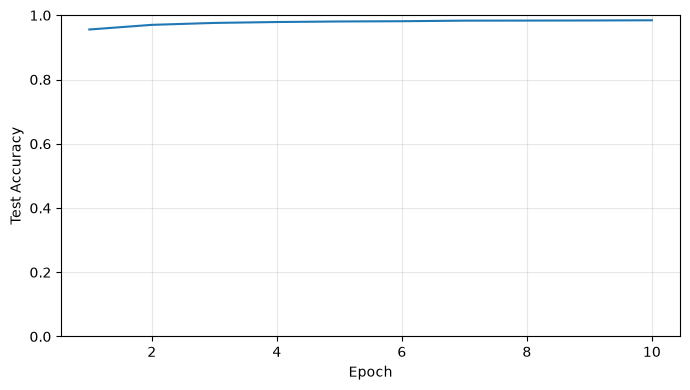

[(1, 0.9556999802589417), (2, 0.9702000021934509), (3, 0.9761999845504761), (4, 0.9789999723434448), (5, 0.9807000160217285), (6, 0.9815000295639038), (7, 0.983299970626831), (8, 0.9835000038146973), (9, 0.9837999939918518), (10, 0.9843999743461609)]


In [6]:
import matplotlib.pyplot as plt

history = trainer.state["log_history"]
rows = [h for h in history if "eval_acc" in h]

epochs = [h["epoch"] + 1 for h in rows]
accs = [h["eval_acc"] for h in rows]

plt.figure(figsize=(7, 4))
plt.plot(epochs, accs, color="C0")
plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.ylim(0.0, 1.0)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(list(zip(epochs, accs)))